Question 6.1 Fit the pipeline chosen in 5.6 on all 1440 videos, the development and the test actors together: once 
5.7 has been answered, the test actors have served their purpose, and a model fitted on more actors 
is expected to generalise at least as well. Save it (for example with joblib), and implement 
load_model and predict in classifier.py. predict normalises the coordinates and computes the 
features with the same functions used for training, imported from the group's own modules, and 
returns the probability of each emotion. An SVC returns probabilities only if it is created with 
probability=True.

In [1]:
import joblib
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# Use the complete dataset: all 1440 videos.
df_all = pd.read_parquet("new_3.2_video_measurements.gzip")

feature_cols = [
    c for c in df_all.select_dtypes(include="number").columns
    if c != "frame"
]

X_all = df_all[feature_cols]
y_all = df_all["emotion"]

final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("svc", SVC(
        kernel="rbf",
        C=1,
        probability=True,
        random_state=42
    ))
])

final_pipeline.fit(X_all, y_all)

joblib.dump(final_pipeline, "../model.joblib")

['../model.joblib']

Question 6.2 With the application, record at least one clip per emotion by each member of the group, saying one 
of the two statements of the dataset. Report the predictions in a table, with a screenshot of the page 
for one of them. Which emotions are recognised, and which are not?

## Q6.2 — Prediction results

,Group Member,Intended Emotion,Statement,Neutral,Calm,Happy,Sad,Angry,Fearful,Disgust,Surprised,Predicted Emotion,Correct?
0,Ricardo Tavares,Neutral,“Kids are talking by the door”,0.36,0.01,0.00,0.26,0.11,0.16,0.01,0.09,Neutral,Yes
1,Ricardo Tavares,Happy,“Kids are talking by the door”,0.01,0.13,0.58,0.05,0.05,0.03,0.02,0.14,Happy,Yes
2,Ricardo Tavares,Calm,“Kids are talking by the door”,0.63,0.01,0.00,0.22,0.06,0.03,0.00,0.04,Neutral,No
3,Ricardo Tavares,Sad,“Kids are talking by the door”,0.03,0.12,0.02,0.57,0.14,0.01,0.07,0.05,Sad,Yes
4,Ricardo Tavares,Angry,“Kids are talking by the door”,0.02,0.03,0.01,0.08,0.46,0.12,0.05,0.23,Angry,Yes
5,Ricardo Tavares,Fearful,“Kids are talking by the door”,0.08,0.01,0.00,0.10,0.13,0.38,0.01,0.30,Fearful,Yes
6,Ricardo Tavares,Disgust,“Kids are talking by the door”,0.02,0.00,0.00,0.21,0.66,0.04,0.02,0.04,Angry,No
7,Ricardo Tavares,Surprised,“Kids are talking by the door”,0.07,0.01,0.00,0.08,0.18,0.39,0.01,0.28,Fearful,No
8,João Neves,Neutral,“Kids are talking by the door”,0.55,0.12,0.00,0.08,0.14,0.08,0.01,0.02,Neutral,Yes
9,João Neves,Happy,“Kids are talking by the door”,0.00,0.03,0.62,0.12,0.07,0.08,0.03,0.04,Happy,Yes


## Example application screenshot

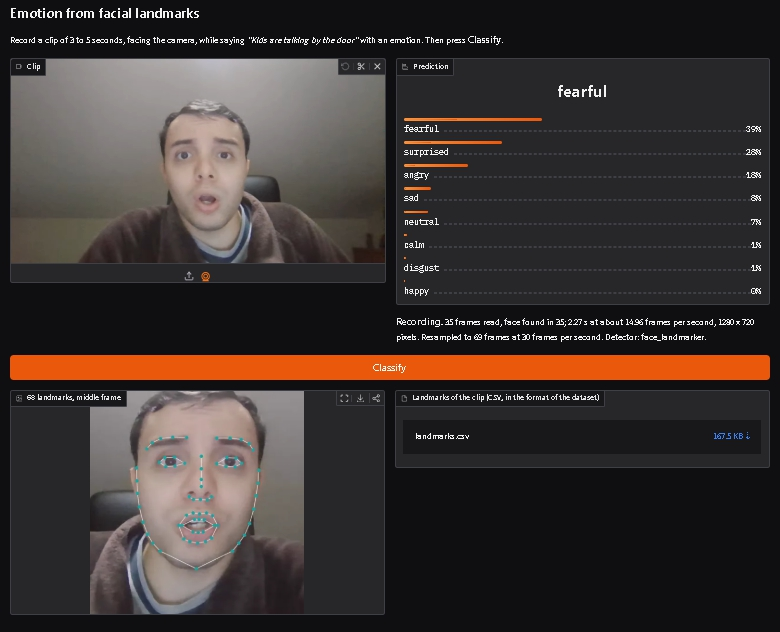

In [2]:
import pandas as pd
from IPython.display import display, Image, Markdown

# Display the table
df = pd.read_excel("6_2_table.xlsx")

display(Markdown("## Q6.2 — Prediction results"))
display(df)

# Display the screenshot
display(Markdown("## Example application screenshot"))
display(Image(filename="6_2_page_screenshot.jpg", width=800))

Of the 16 clips (8 emotions × 2 people), 9 were classified correctly. Neutral, Happy, Sad and Angry were recognised in both clips. Disgust and Fearful were recognised in one of the two clips: Ricardo’s Disgust was classified as Angry, and João’s Fearful as Neutral. Calm and Surprised were never recognised: Calm was predicted as Neutral and as Sad, and Surprised as Fearful and as Angry.

Question 6.3 The application differs from the data in the tracker (MediaPipe instead of OpenFace), in the camera 
and the recording conditions, and in the person. For the clips of 6.2, locate the value of each feature 
in its distribution in the training data, for example as a percentile. Which features fall outside the 
range of the training data, and why? Which of the two normalisations of 2.1 would have failed in the 
application, and why?

Training videos used: 1440 | features compared: 55
Consistency check on 5 training videos: max relative difference = 1.60e-15
Application recordings processed: 16 | people: ['Joao', 'Ricardo']


,recording,n_frames
0,Joao_angry_landmarks.csv,91
1,Joao_calm_landmarks.csv,113
2,Joao_disgust_landmarks.csv,92
3,Joao_fearful_landmarks.csv,101
4,Joao_happy_landmarks.csv,88
5,Joao_neutral_landmarks.csv,99
6,Joao_sad_landmarks.csv,81
7,Joao_surprised_landmarks.csv,90
8,Ricardo_angry_landmarks.csv,63
9,Ricardo_calm_landmarks.csv,83


## Features outside the training min–max range (out of 16 clips)

,feature,measure,statistic,n_outside,n_below,n_above,median_dist_outside,frac_clips_outside
0,M6_v,M6,v,11,11,0,-0.057307,0.6875
1,M6_E,M6,E,10,10,0,-0.002279,0.6250
2,M9_E,M9,E,9,9,0,-0.007638,0.5625
3,M9_v,M9,v,9,9,0,-0.087875,0.5625
4,M11_E,M11,E,7,7,0,-0.000223,0.4375
5,M11_v,M11,v,7,7,0,-0.008564,0.4375
6,M4_E,M4,E,7,7,0,-0.000210,0.4375
7,M4_v,M4,v,7,7,0,-0.019536,0.4375
8,M5_E,M5,E,6,6,0,-0.000099,0.3750
9,M5_v,M5,v,5,5,0,-0.003518,0.3125


## % of clip-feature values outside the range, by type of statistic

...

,% outside
measure,
M1,0.0
M2,6.2
M3,1.2
M4,18.8
M5,15.0
M6,26.2
M7,7.5
M8,8.8
M9,36.2


## Number of clips outside the range: measure x statistic

statistic,mean,std,range,v,E
measure,,,,,
M1,0,0,0,0,0
M2,4,0,0,0,1
M3,0,0,0,0,1
M4,0,0,1,7,7
M5,1,0,0,5,6
M6,0,0,0,11,10
M7,0,0,0,4,2
M8,3,0,0,2,2
M9,5,1,5,9,9


## Summary per recording

,recording,person,emotion,outside_range,outside_central_95,outside_range_same_emotion,worst_dist_outside
0,Joao_angry_landmarks.csv,Joao,Angry,0,9,2,0.000000
1,Joao_calm_landmarks.csv,Joao,Calm,0,3,2,0.000000
2,Joao_disgust_landmarks.csv,Joao,Disgust,0,3,0,0.000000
3,Joao_fearful_landmarks.csv,Joao,Fearful,8,11,9,0.019985
4,Joao_happy_landmarks.csv,Joao,Happy,2,7,8,0.033714
5,Joao_neutral_landmarks.csv,Joao,Neutral,4,6,9,0.057307
6,Joao_sad_landmarks.csv,Joao,Sad,1,7,3,0.195780
7,Joao_surprised_landmarks.csv,Joao,Surprised,2,5,6,0.103539
8,Ricardo_angry_landmarks.csv,Ricardo,Angry,13,24,23,0.068988
9,Ricardo_calm_landmarks.csv,Ricardo,Calm,12,30,23,0.087875


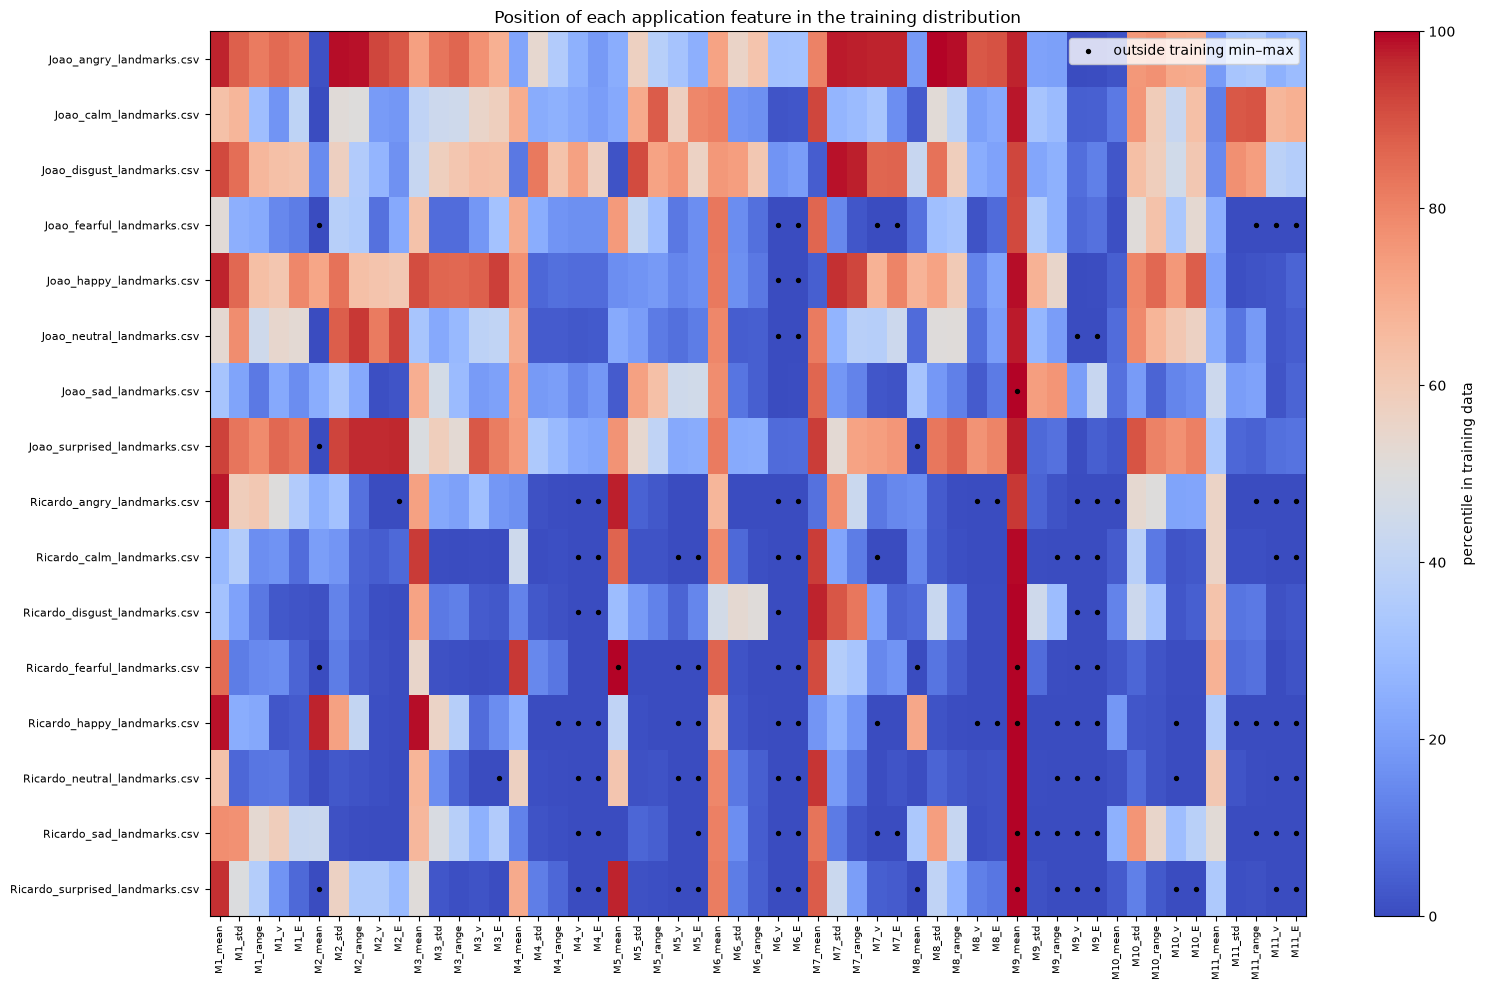

Saved Q6_3_*.csv tables in: c:\Users\rjorg\Desktop\Universidade\Universidade de Coimbra\Introducao_a_Aprendizagem_Computacional\projeto\IML_project_app\app\fase1


In [3]:
from pathlib import Path
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# features.py builds its frame column by column; the warning is harmless.
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
BASE = Path.cwd()
RECORDINGS_DIR = BASE / "6_3_landmark_recordings"
TRAINING_FILE = BASE / "new_3.2_video_measurements.gzip"
FRAME_TABLE = BASE / "t1.1.gzip"          # optional: only for the consistency check

feature_candidates = [
    BASE / "features.py",
    BASE.parent / "features.py",
    BASE.parent.parent / "features.py",
]
FEATURES_FILE = next((p for p in feature_candidates if p.exists()), None)

if not RECORDINGS_DIR.is_dir():
    raise FileNotFoundError(f"Recordings folder not found: {RECORDINGS_DIR}")
if not TRAINING_FILE.exists():
    raise FileNotFoundError(f"Training feature file not found: {TRAINING_FILE}")
if FEATURES_FILE is None:
    raise FileNotFoundError("Could not find features.py (the application's module).")

# The exact feature code used by the application
sys.path.insert(0, str(FEATURES_FILE.parent))
from features import extract_video_features, FEATURE_NAMES

feature_cols = list(FEATURE_NAMES)        # the 55 features, in the model's order

# --------------------------------------------------
# 2. Training distribution (all 1440 videos: what the final model was fitted on)
# --------------------------------------------------
training = pd.read_parquet(TRAINING_FILE)
missing_cols = set(feature_cols) - set(training.columns)
if missing_cols:
    raise ValueError(f"Training table lacks features: {sorted(missing_cols)}")

training[feature_cols] = (
    training[feature_cols].apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
training = training.dropna(subset=feature_cols).reset_index(drop=True)
print("Training videos used:", len(training), "| features compared:", len(feature_cols))

# --------------------------------------------------
# 2b. Consistency check: does features.py reproduce the training table?
#     If not, every "outside the range" result below could be a code mismatch
#     and not a tracker/camera/person effect.
# --------------------------------------------------
if FRAME_TABLE.exists():
    frames_all = pd.read_parquet(FRAME_TABLE)
    sample_videos = training["video"].sample(5, random_state=0)
    worst = 0.0
    for v in sample_videos:
        got = extract_video_features(frames_all[frames_all["video"] == v])[feature_cols].iloc[0].to_numpy(float)
        ref = training.loc[training["video"] == v, feature_cols].iloc[0].to_numpy(float)
        worst = max(worst, np.max(np.abs(got - ref) / (np.abs(ref) + 1e-12)))
    print(f"Consistency check on 5 training videos: max relative difference = {worst:.2e}")
    if worst > 1e-6:
        print("WARNING: features.py does not reproduce the training features.")
    del frames_all
else:
    print("Consistency check skipped (t1.1.gzip not found).")

# --------------------------------------------------
# 3. Features of each application recording
#    File names: <person>_<emotion>_landmarks.csv
# --------------------------------------------------
def parse_name(path):
    m = re.match(r"(?P<person>.+?)_(?P<emotion>[A-Za-z]+)_landmarks", path.stem)
    if m:
        return m.group("person"), m.group("emotion").capitalize()
    return path.stem, None

landmark_files = sorted(RECORDINGS_DIR.rglob("*.csv"))
if not landmark_files:
    raise FileNotFoundError(f"No CSV files found in {RECORDINGS_DIR}")

rows = []
for csv_path in landmark_files:
    person, emotion = parse_name(csv_path)
    frames = pd.read_csv(csv_path)
    values = extract_video_features(frames)[feature_cols].iloc[0]
    rows.append({"recording": csv_path.name, "person": person,
                 "emotion": emotion, "n_frames": len(frames), **values.to_dict()})

recording_features = pd.DataFrame(rows)
print("Application recordings processed:", len(recording_features),
      "| people:", sorted(recording_features["person"].unique()))
display(recording_features[["recording", "n_frames"]])

# --------------------------------------------------
# 4. Locate every value in the training distribution
# --------------------------------------------------
stat_of = lambda f: f.rsplit("_", 1)[1]          # mean / std / range / v / E
measure_of = lambda f: f.rsplit("_", 1)[0]       # M1 ... M11

ref_all = {f: np.sort(training[f].to_numpy(float)) for f in feature_cols}
ref_emo = {e: {f: np.sort(g[f].to_numpy(float)) for f in feature_cols}
           for e, g in training.groupby("emotion")}

def pct(sorted_ref, value):
    """Percentage of training values <= value (0 or 100 means outside the range)."""
    return 100.0 * np.searchsorted(sorted_ref, value, side="right") / len(sorted_ref)

def distance_outside(ref, value):
    """0 if inside [min, max]; otherwise signed distance to the nearest bound,
    in units of the training range (max - min). Shows HOW FAR outside, which
    a percentile of 0 or 100 cannot."""
    lo, hi = ref[0], ref[-1]
    span = hi - lo if hi > lo else 1.0
    return (value - lo) / span if value < lo else (value - hi) / span if value > hi else 0.0

comparison_rows = []
for _, rec in recording_features.iterrows():
    for f in feature_cols:
        v = float(rec[f])
        r = ref_all[f]
        q1, med, q3 = np.percentile(r, [25, 50, 75])
        d_out = distance_outside(r, v)
        row = {
            "recording": rec["recording"], "person": rec["person"], "emotion": rec["emotion"],
            "feature": f, "measure": measure_of(f), "statistic": stat_of(f),
            "value": v,
            "train_min": r[0], "train_p2.5": np.percentile(r, 2.5), "train_median": med,
            "train_p97.5": np.percentile(r, 97.5), "train_max": r[-1],
            "percentile": pct(r, v),
            "robust_z": (v - med) / (q3 - q1) if q3 > q1 else np.nan,   # distance from median in IQRs
            "outside_range": d_out != 0.0,
            "direction": "below" if d_out < 0 else "above" if d_out > 0 else "inside",
            "dist_outside_range": d_out,           # signed, in training-range units
            "outside_central_95": (v < np.percentile(r, 2.5)) or (v > np.percentile(r, 97.5)),
        }
        # Same-emotion reference: a value can be inside the pooled range
        # but extreme for the emotion that was actually performed.
        if rec["emotion"] in ref_emo:
            re_ = ref_emo[rec["emotion"]][f]
            row["percentile_same_emotion"] = pct(re_, v)
            row["outside_range_same_emotion"] = distance_outside(re_, v) != 0.0
        else:
            row["percentile_same_emotion"] = np.nan
            row["outside_range_same_emotion"] = np.nan
        comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows)

# --------------------------------------------------
# 5. Which features fall outside, and which kind of feature?
# --------------------------------------------------
n_clips = recording_features.shape[0]

per_feature = (
    comparison.groupby(["feature", "measure", "statistic"])
    .agg(n_outside=("outside_range", "sum"),
         n_below=("direction", lambda s: (s == "below").sum()),
         n_above=("direction", lambda s: (s == "above").sum()),
         median_dist_outside=("dist_outside_range", lambda s: s[s != 0].median() if (s != 0).any() else 0.0))
    .reset_index()
    .sort_values(["n_outside", "feature"], ascending=[False, True])
    .reset_index(drop=True)
)
per_feature["frac_clips_outside"] = per_feature["n_outside"] / n_clips

display(Markdown(f"## Features outside the training min–max range (out of {n_clips} clips)"))
display(per_feature[per_feature["n_outside"] > 0])

# Pattern by type of statistic and by measure (share of clip x feature values outside)
order_stats = ["mean", "std", "range", "v", "E"]
by_statistic = (comparison.groupby("statistic")["outside_range"].mean()
                .reindex(order_stats).mul(100).round(1).rename("% outside"))
by_measure = comparison.groupby("measure")["outside_range"].mean().mul(100).round(1).rename("% outside")
by_measure = by_measure.reindex([f"M{i}" for i in range(1, 12)])

display(Markdown("## % of clip-feature values outside the range, by type of statistic"))
display(by_statistic.to_frame())
display(Markdown("## ... and by measure"))
display(by_measure.to_frame())

display(Markdown("## Number of clips outside the range: measure x statistic"))
display(per_feature.pivot(index="measure", columns="statistic", values="n_outside")
        .reindex(index=[f"M{i}" for i in range(1, 12)], columns=order_stats))

# --------------------------------------------------
# 6. Summary per recording
# --------------------------------------------------
summary = (
    comparison.groupby(["recording", "person", "emotion"], dropna=False)
    .agg(outside_range=("outside_range", "sum"),
         outside_central_95=("outside_central_95", "sum"),
         outside_range_same_emotion=("outside_range_same_emotion", "sum"),
         worst_dist_outside=("dist_outside_range", lambda s: s.abs().max()))
    .reset_index()
)
display(Markdown("## Summary per recording"))
display(summary)

# --------------------------------------------------
# 7. Figure: percentile of every feature for every clip
#    (black dot = outside the training min–max)
# --------------------------------------------------
pct_matrix = comparison.pivot(index="recording", columns="feature", values="percentile")[feature_cols]
out_matrix = comparison.pivot(index="recording", columns="feature", values="outside_range")[feature_cols]

fig, ax = plt.subplots(figsize=(16, 0.5 * n_clips + 2))
im = ax.imshow(pct_matrix.values, aspect="auto", cmap="coolwarm", vmin=0, vmax=100)
ys, xs = np.where(out_matrix.values.astype(bool))
ax.scatter(xs, ys, s=8, c="black", label="outside training min–max")
ax.set_xticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=90, fontsize=7)
ax.set_yticks(range(n_clips))
ax.set_yticklabels(pct_matrix.index, fontsize=8)
plt.colorbar(im, ax=ax, label="percentile in training data")
ax.legend(loc="upper right")
ax.set_title("Position of each application feature in the training distribution")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Export tables for the report
# --------------------------------------------------
comparison.to_csv("Q6_3_all_feature_comparisons.csv", index=False)
comparison[comparison["outside_range"]].to_csv("Q6_3_outside_training_range.csv", index=False)
per_feature.to_csv("Q6_3_per_feature_summary.csv", index=False)
summary.to_csv("Q6_3_recording_summary.csv", index=False)
print("Saved Q6_3_*.csv tables in:", BASE)

In [4]:
for p in sorted(RECORDINGS_DIR.rglob("*.csv")):
    f = pd.read_csv(p)
    c = f[[f"{a}_{k}" for k in range(68) for a in "xy"]].to_numpy()
    d2 = np.abs(c[2:] - 2*c[1:-1] + c[:-2]).mean(axis=1)
    a, b = d2[0::2].mean(), d2[1::2].mean()
    print(f"{p.name:35s} ratio = {min(a,b)/max(a,b):.2f}")

Joao_angry_landmarks.csv            ratio = 0.99
Joao_calm_landmarks.csv             ratio = 0.95
Joao_disgust_landmarks.csv          ratio = 0.91
Joao_fearful_landmarks.csv          ratio = 0.99
Joao_happy_landmarks.csv            ratio = 0.93
Joao_neutral_landmarks.csv          ratio = 0.85
Joao_sad_landmarks.csv              ratio = 0.84
Joao_surprised_landmarks.csv        ratio = 0.97
Ricardo_angry_landmarks.csv         ratio = 0.19
Ricardo_calm_landmarks.csv          ratio = 0.35
Ricardo_disgust_landmarks.csv       ratio = 0.16
Ricardo_fearful_landmarks.csv       ratio = 0.32
Ricardo_happy_landmarks.csv         ratio = 0.27
Ricardo_neutral_landmarks.csv       ratio = 0.16
Ricardo_sad_landmarks.csv           ratio = 0.24
Ricardo_surprised_landmarks.csv     ratio = 0.15


For each of the 16 clips (8 emotions × 2 people), the 55 features were computed with the application’s own code (features.py), which reproduces the training features of five training videos to a relative difference of 10⁻¹⁵, so the differences below are not caused by the code. Each value was then located in the distribution of the 1440 training videos by its percentile; a value outside the training minimum–maximum has a percentile of 0 or 100.

Which features fall outside the range. The problem is concentrated in particular features. The dynamic features are the most affected: 27% of the values of v and 26% of the values of E fall outside the range, always below the training minimum, against 8% for the mean, 6% for the range and 1% for the standard deviation. By measure, the most affected are M9 (36% of values), M6 (26%), M11 (24%), M4 (19%) and M5 (15%), which are the eyebrow and eye measures. M1 (mouth opening) is never outside the range, and M2 and M3 almost never. Some static features also fall outside: M9_mean is above the training maximum in 5 clips, and M2_mean and M8_mean are below the minimum in 4 and 3 clips. The distances are small; in no clip is a value more than about 0.2 of the training range beyond the limit.

The clips differ greatly by person. Ricardo’s eight clips have between 5 and 19 features outside the range, while João’s have between 0 and 8, and three of João’s clips have none. Both used the same tracker, so the camera and the recording conditions are the more likely explanation.

The dynamic features (v and E) are computed from the differences between consecutive frames, so they are sensitive to the noise level of the tracker and to the frame-to-frame behaviour of the camera. MediaPipe and OpenFace have different noise levels, and the eye and eyebrow measures move little, so noise makes up a large share of their v and E. A lower noise level, or a recording that is smoother between frames (as can happen with a different camera or lighting), places them below the training minimum. 
The static features (M9_mean, M2_mean, M8_mean) are affected because the two trackers place the landmarks at slightly different points, and because the person has a different face shape, camera angle and distance. M9_mean is the clearest case: it is positive in the application, while in the training data it is always negative. The mouth measures are not affected, probably because the mouth moves much more than the tracker noise and its landmarks are defined clearly.

The normalisation by the image size (1280 × 720) would have failed. The application gives the landmarks in pixels of the webcam frame, whose size is not necessarily 1280 × 720. Dividing by a fixed image size makes every length depend on the camera resolution and on how far the person sits from the camera, so almost all features would fall far outside the training range. If the aspect ratio differs, the two axes would also be scaled by different factors, which distorts the face. The normalisation by the inter-ocular distance d scales both axes by the same factor in each frame, so it cancels the face size and the distance to the camera. It is the one used in the application.

Question 6.4 The application resamples the landmarks to 30 frames per second. Which statistics of Table 3 would 
change, and in which direction, if the clips of a camera recording at 15 frames per second reached 
predict without resampling? Why must the frame rate seen by the model match that of the training 
data?

The statistics of Table 3 are the mean, standard deviation and range of each measure, and the mean absolute velocity v and the movement energy E. The first three describe the values of the measure. v and E are computed from the differences between consecutive frames, so they depend on the time between frames.

If a 15 fps clip reached predict without resampling, consecutive frames would be 1/15 s apart, but the model would treat them as 1/30 s apart. The mean, standard deviation and range would stay about the same, since the values of the measure do not change; only fewer of them are sampled. v would increase, by up to a factor of two, because the difference between consecutive measurements spans twice the time. E would increase by up to a factor of four, as it scales with the square of the step. These factors apply to smooth movements; tracker noise does not grow with the time step, so on noisy measures the increase would be smaller. The direction would still be upwards.

The frame rate seen by the model must match the training data because v and E are per-frame quantities, not per-second ones. The model learned the relation between emotion and the amount of movement per 1/30 s. With 15 fps input, the same expression would produce values of v and E that are too large, so a slow, calm movement would look like a fast, energetic one. The inputs would then fall in a region of feature space the model did not learn, and its decision boundaries would no longer apply. This is why the application resamples to 30 fps.